In [1]:
import pandas as pd
import glob
import os
import matplotlib.pyplot as plt

Optimal Alpha: 0.15
Average Percentage Within Range: 44.77%


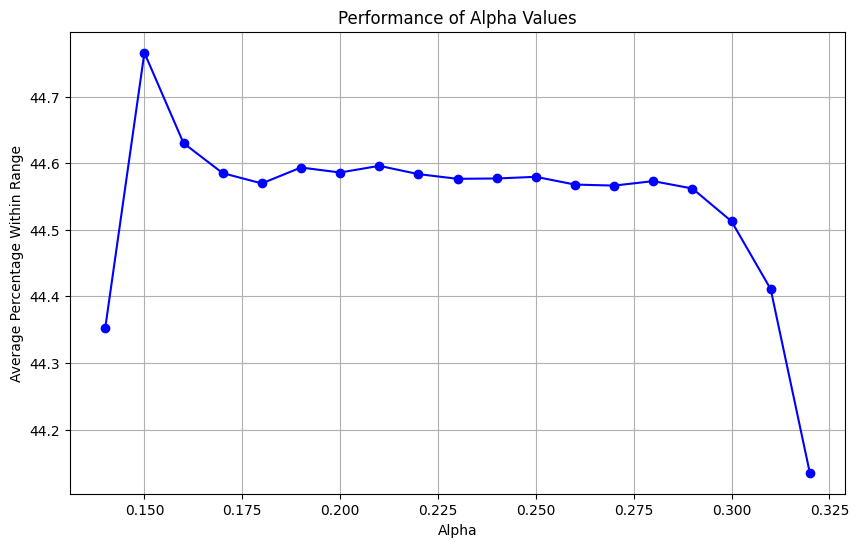

In [2]:
alpha_values = [round(i * 0.01, 2) for i in range(51)]
votable_supply_data = pd.read_csv("../../../data/votable_supply-dhruvi/data/indexes.csv")
file_paths = glob.glob("../data/weight_combinations_results/*.csv")

results = []

for file_path in file_paths:
    file_name = os.path.basename(file_path)
    weights = "_".join(file_name.replace("results_", "").replace(".csv", "").split('_')[1::2])
    F_data = pd.read_csv(file_path)
    merged_data = pd.merge(F_data, votable_supply_data, on="Date")
    
    best_alpha = None
    best_percentage = 0
    
    for alpha in alpha_values:
        merged_data["Voriginal"] = merged_data["Votable Supply"]
        merged_data["Proportional Value"] = merged_data["Voriginal"] * (1 + alpha * (merged_data["F"] - 1))
        merged_data["Lower Bound"] = 1.5 * merged_data["Voriginal"]
        merged_data["Upper Bound"] = 2.0 * merged_data["Voriginal"]
        merged_data["Proportional Value Within Range"] = (
            (merged_data["Proportional Value"] >= merged_data["Lower Bound"]) & 
            (merged_data["Proportional Value"] <= merged_data["Upper Bound"])
        )
        percentage_within_range = 100 * merged_data["Proportional Value Within Range"].sum() / len(merged_data)
        
        if percentage_within_range > best_percentage:
            best_alpha = alpha
            best_percentage = percentage_within_range
    
    results.append({
        "Weights": weights,
        "Optimal Alpha": best_alpha,
        "Percentage Within Range": best_percentage
    })

results_df = pd.DataFrame(results)
output_path = "../../../data/votable_supply-dhruvi/data/optimal_alpha_results.csv"
results_df.to_csv(output_path, index=False)

data = pd.read_csv("../../../data/votable_supply-dhruvi/data/optimal_alpha_results.csv")
alpha_summary = data.groupby("Optimal Alpha", as_index=False)["Percentage Within Range"].mean()
best_alpha = alpha_summary.loc[alpha_summary["Percentage Within Range"].idxmax()]

print(f"Optimal Alpha: {best_alpha['Optimal Alpha']}")
print(f"Average Percentage Within Range: {best_alpha['Percentage Within Range']:.2f}%")

plt.figure(figsize=(10, 6))
plt.plot(alpha_summary["Optimal Alpha"], alpha_summary["Percentage Within Range"], marker='o', color='blue')
plt.title("Performance of Alpha Values")
plt.xlabel("Alpha")
plt.ylabel("Average Percentage Within Range")
plt.grid(True)
plt.show()
